DATA VALIDATION: PASSED
Số quan sát: 20
Giai đoạn: 2005–2024
Xuất khẩu tăng 13.5 lần; nhập khẩu tăng 9.5 lần
Đã lưu biểu đồ PNG và SVG.


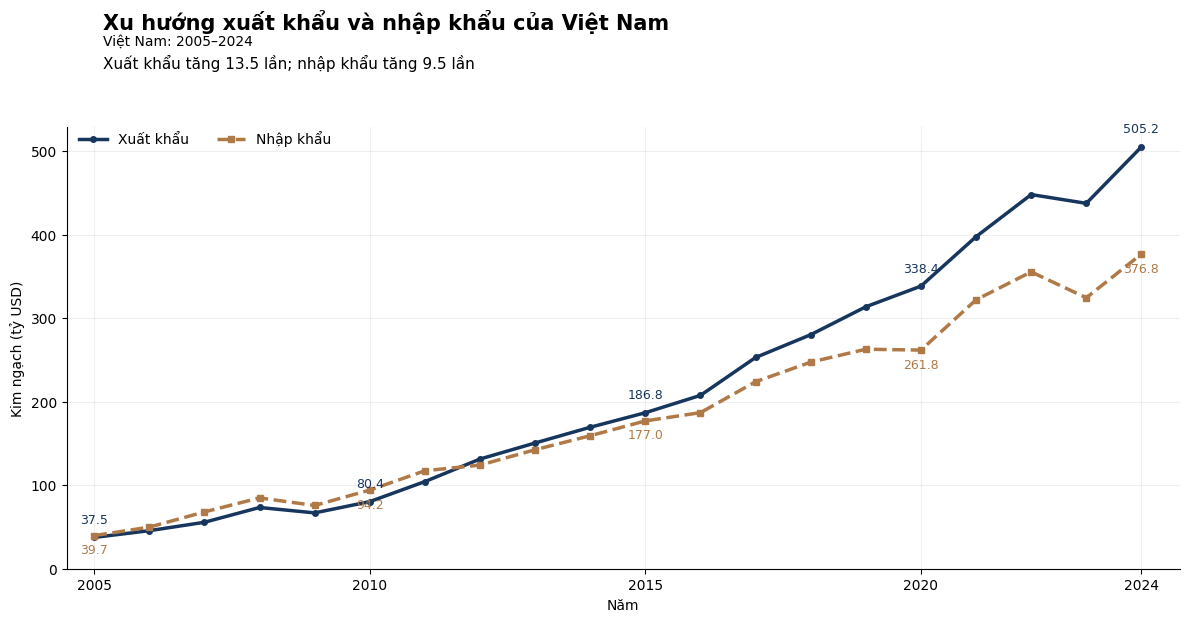

In [9]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

# ==========================================
# 1. TÌM ROOT VÀ ĐỌC DỮ LIỆU
# ==========================================

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "data/clean/trade_year.csv").is_file()),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy data/clean/trade_year.csv trong repository."
    )

DATA_PATH = ROOT / "data/clean/trade_year.csv"
OUT_DIR = ROOT / "evidence/ai_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA_PATH,
    dtype={"country_iso3": "string"},
    encoding="utf-8-sig"
)

# ==========================================
# 2. LÀM SẠCH VÀ KIỂM TRA DỮ LIỆU
# ==========================================

df = df[
    (df["country_iso3"].str.strip() == "VNM") &
    (pd.to_numeric(df["year"], errors="coerce").between(2005, 2024))
].copy()

df["year"] = pd.to_numeric(df["year"], errors="raise").astype(int)

df = df.sort_values("year").reset_index(drop=True)

assert len(df) == 20, f"Sai số quan sát: {len(df)}"
assert df["year"].is_unique, "Phát hiện năm trùng lặp."

for col in ["export_usd", "import_usd"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
    assert df[col].notna().all(), f"{col} có dữ liệu thiếu."
    assert np.isfinite(df[col]).all(), f"{col} có giá trị không hữu hạn."
    assert df[col].ge(0).all(), f"{col} có giá trị âm."

assert df["year"].tolist() == list(range(2005, 2025))

df["export_bn"] = df["export_usd"] / 1e9
df["import_bn"] = df["import_usd"] / 1e9

# ==========================================
# 3. TÍNH TĂNG TRƯỞNG
# ==========================================

first = df.iloc[0]
last = df.iloc[-1]

export_ratio = last["export_usd"] / first["export_usd"]
import_ratio = last["import_usd"] / first["import_usd"]

title = (
    f"Xuất khẩu tăng {export_ratio:.1f} lần; "
    f"nhập khẩu tăng {import_ratio:.1f} lần"
)

# ==========================================
# 4. VẼ BIỂU ĐỒ - KHÔNG CÓ BẢNG
# ==========================================

fig, ax = plt.subplots(figsize=(12, 6.5))

# Xuất khẩu
ax.plot(
    df["year"], df["export_bn"],
    color="#17365D",
    linestyle="-",
    marker="o",
    markersize=4,
    linewidth=2.5,
    label="Xuất khẩu"
)

# Nhập khẩu
ax.plot(
    df["year"], df["import_bn"],
    color="#B07A48",
    linestyle="--",
    marker="s",
    markersize=4,
    linewidth=2.5,
    label="Nhập khẩu"
)

# Các mốc năm
ticks = [2005, 2010, 2015, 2020, 2024]

for year in ticks:
    ax.axvline(
        year,
        color="gray",
        alpha=0.12,
        linewidth=0.8
    )

# Nhãn dữ liệu tại các mốc năm
for col, color, offset in [
    ("export_bn", "#17365D", 10),
    ("import_bn", "#B07A48", -13)
]:
    for row in df[df["year"].isin(ticks)].itertuples():
        value = getattr(row, col)

        ax.annotate(
            f"{value:.1f}",
            (row.year, value),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            fontsize=9,
            color=color,
            fontweight="medium"
        )

# Trục và định dạng
ax.set_xlim(2004.5, 2024.7)
ax.set_xticks(ticks)
ax.set_xlabel("Năm")
ax.set_ylabel("Kim ngạch (tỷ USD)")

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

ax.set_ylim(bottom=0)

# Tiêu đề và thông tin bên dưới title
fig.suptitle(
    "Xu hướng xuất khẩu và nhập khẩu của Việt Nam",
    fontsize=15,
    fontweight="bold",
    color="black",
    x=0.09,
    y=0.97,
    ha="left"
)

fig.text(
    0.09, 0.915,
    "Việt Nam: 2005–2024",
    fontsize=10,
    color="black",
    ha="left"
)

fig.text(
    0.09, 0.88,
    title,
    fontsize=11,
    color="black",
    ha="left"
)

# Chừa khoảng trống phía trên cho title và subtitle
plt.tight_layout(rect=[0, 0.02, 1, 0.84])

# Chú giải
ax.legend(
    loc="upper left",
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False
)

# Lưới và loại bỏ viền thừa
ax.grid(axis="y", alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout(rect=[0, 0.02, 1, 0.88])

# ==========================================
# 5. LƯU BIỂU ĐỒ
# ==========================================

output_png = OUT_DIR / "corrected_chart.png"
output_svg = OUT_DIR / "corrected_chart.svg"

fig.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    output_svg,
    bbox_inches="tight",
    facecolor="white"
)

assert output_png.exists() and output_png.stat().st_size > 0
assert output_svg.exists() and output_svg.stat().st_size > 0

print("DATA VALIDATION: PASSED")
print("Số quan sát:", len(df))
print("Giai đoạn: 2005–2024")
print(title)
print("Đã lưu biểu đồ PNG và SVG.")

plt.show()
